# Sales Performance Dashboard and Analysis — 2026
### Phase 2: Python / Pandas Analysis

**Dataset:** `retail_sales_12000.csv` — 12,000 retail transactions, 2023–2025.

This notebook covers:
1. Setup & data loading
2. Data cleaning (from Phase 1 findings)
3. Core KPIs
4. Time trends (monthly, yearly, growth rate, seasonality)
5. Category / Product / Region / Segment performance
6. Discount vs Profit analysis
7. Charts (saved to `outputs/charts/`)

> **How to use this notebook:** Run each cell top to bottom (Shift+Enter). Markdown cells explain *why* each step matters and what to check in the output before moving on.

## Step 1 — Import Libraries
We use **pandas** for data manipulation, **numpy** for numeric operations, and **matplotlib/seaborn** for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

# Create output folder for charts
os.makedirs('outputs/charts', exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Step 2 — Load the Dataset
We load the raw CSV exactly as provided. **Do not modify the raw file** — all cleaning happens on a copy in memory.

In [2]:
df = pd.read_csv('../Data/retail_sales_12000.csv')
print("Shape:", df.shape)
df.head()

Shape: (12000, 14)


,Order_ID,Order_Date,Region,Category,Product,Customer_ID,Customer_Segment,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method
0,ORD111371,2023-01-01,Central,Clothing,Backpack,10105,Corporate,6,104.18,0.00,625.07,410.36,214.71,UPI
1,ORD101402,2023-01-01,West,Home & Kitchen,Cookware Set,12082,Small Business,1,164.79,0.00,164.79,129.29,35.50,Credit Card
2,ORD101195,2023-01-01,West,Electronics,Keyboard,10945,Small Business,1,411.88,0.00,411.88,290.20,121.67,UPI
3,ORD102407,2023-01-01,West,Electronics,Smartphone,11150,Consumer,5,494.19,0.05,2347.40,1440.68,906.72,Debit Card
4,ORD108270,2023-01-01,South,Clothing,T-Shirt,11897,Small Business,2,91.99,0.10,165.58,91.72,73.86,UPI


## Step 3 — Data Cleaning
From Phase 1, we confirmed: no missing values, no duplicates, all categorical values are clean. The only real cleaning needed is:
1. Convert `Order_Date` from text to a proper datetime type.
2. Round `Sales`, `Cost`, `Profit` to 2 decimals (remove floating-point noise).
3. Add derived time columns (`Year`, `Month`, `Month_Name`, `Year_Month`) for trend analysis.
4. Add `Profit_Margin_%` per order.

**Check after running:** confirm `Order_Date` dtype is `datetime64`, and that the new columns look correct in the preview.

In [3]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

df['Sales'] = df['Sales'].round(2)
df['Cost'] = df['Cost'].round(2)
df['Profit'] = df['Profit'].round(2)

df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
df['Year_Month'] = df['Order_Date'].dt.to_period('M').astype(str)

df['Profit_Margin_%'] = (df['Profit'] / df['Sales'] * 100).round(2)

print(df.dtypes)
df[['Order_Date','Year','Month_Name','Year_Month','Profit_Margin_%']].head()

Order_ID                       str
Order_Date          datetime64[us]
Region                         str
Category                       str
Product                        str
Customer_ID                  int64
Customer_Segment               str
Quantity                     int64
Unit_Price                 float64
Discount                   float64
Sales                      float64
Cost                       float64
Profit                     float64
Payment_Method                 str
Year                         int32
Month                        int32
Month_Name                     str
Year_Month                     str
Profit_Margin_%            float64
dtype: object


,Order_Date,Year,Month_Name,Year_Month,Profit_Margin_%
0,2023-01-01,2023,Jan,2023-01,34.35
1,2023-01-01,2023,Jan,2023-01,21.54
2,2023-01-01,2023,Jan,2023-01,29.54
3,2023-01-01,2023,Jan,2023-01,38.63
4,2023-01-01,2023,Jan,2023-01,44.61


In [4]:
# Save cleaned dataset for reuse in Excel/Power BI/Tableau phases
df.to_csv('cleaned_sales.csv', index=False)
print("Saved cleaned_sales.csv —", df.shape)

Saved cleaned_sales.csv — (12000, 19)


## Step 4 — Core KPIs
These are the headline numbers that will become the KPI cards on the Power BI Executive Overview page:
- **Total Sales** — sum of revenue
- **Total Profit** — sum of profit
- **Total Orders** — count of unique orders
- **Total Quantity** — total units sold
- **Average Order Value (AOV)** — Total Sales ÷ Total Orders
- **Profit Margin %** — Total Profit ÷ Total Sales × 100

**Check:** these numbers should look like plausible round-number scale figures — no extreme values.

In [5]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_quantity = df['Quantity'].sum()
avg_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

kpis = pd.DataFrame({
    'Metric': ['Total Sales', 'Total Profit', 'Total Orders', 'Total Quantity', 'Avg Order Value', 'Profit Margin %'],
    'Value': [f"${total_sales:,.2f}", f"${total_profit:,.2f}", f"{total_orders:,}",
              f"{total_quantity:,}", f"${avg_order_value:,.2f}", f"{profit_margin:.2f}%"]
})
kpis

,Metric,Value
0,Total Sales,"$9,779,538.30"
1,Total Profit,"$3,087,335.94"
2,Total Orders,"12,000"
3,Total Quantity,"48,120"
4,Avg Order Value,$814.96
5,Profit Margin %,31.57%


## Step 5 — Monthly & Yearly Sales Trend
Grouping by `Year_Month` shows how revenue moves over time — this feeds the "Monthly Sales Trend" visual in Power BI Page 1.

**What this chart should communicate:** whether the business is growing, flat, or seasonal, and whether any specific month stands out (unusually high/low).

In [6]:
monthly = df.groupby('Year_Month').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index().sort_values('Year_Month')

monthly['Growth_Rate_%'] = monthly['Sales'].pct_change().mul(100).round(2)
monthly.head(12)

,Year_Month,Sales,Profit,Orders,Growth_Rate_%
0,2023-01,287955.89,91183.94,351,NaN
1,2023-02,220781.97,68410.69,272,-23.33
2,2023-03,291186.11,92083.71,318,31.89
3,2023-04,262908.55,82284.02,331,-9.71
4,2023-05,260386.44,82105.37,336,-0.96
5,2023-06,302655.24,94663.70,330,16.23
6,2023-07,276548.72,85198.58,327,-8.63
7,2023-08,296497.30,93426.08,349,7.21
8,2023-09,271794.65,86906.34,337,-8.33
9,2023-10,230247.35,73264.51,282,-15.29


In [7]:
yearly = df.groupby('Year').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index()
yearly

,Year,Sales,Profit,Orders
0,2023,3302726.78,1039727.81,3960
1,2024,3272828.97,1037330.14,4028
2,2025,3203982.55,1010277.99,4012


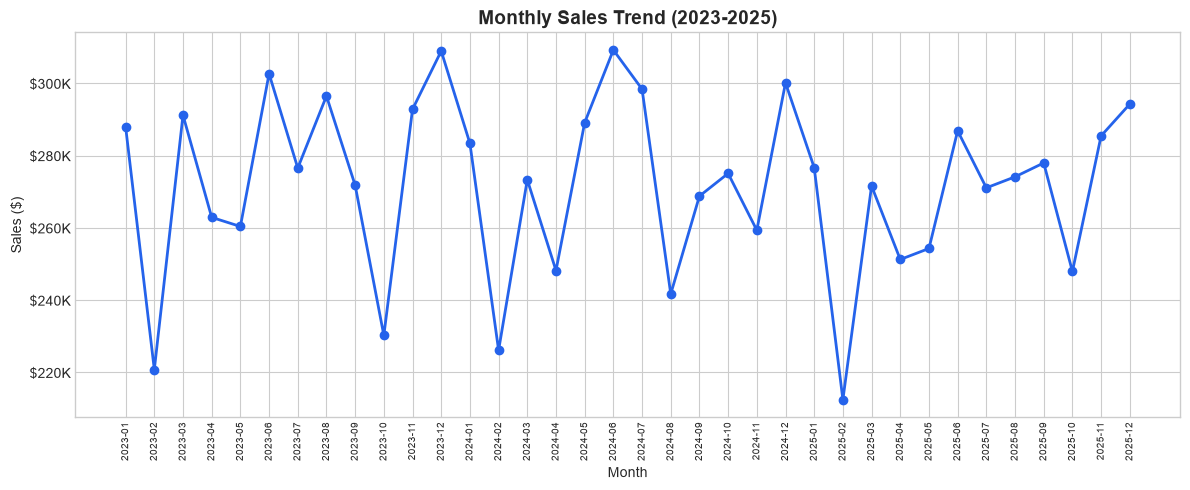

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly['Year_Month'], monthly['Sales'], marker='o', color='#2563eb', linewidth=2)
ax.set_title('Monthly Sales Trend (2023-2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1000:.0f}K'))
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig('outputs/charts/01_monthly_sales_trend.png', dpi=150)
plt.show()

## Step 6 — Monthly Growth Rate
`Growth_Rate_%` (calculated above with `pct_change()`) shows month-over-month % change in sales. Large swings (e.g. a big drop in February each year) are worth flagging as a seasonal pattern rather than a problem — we confirm this in Step 9 (Seasonal Trend).

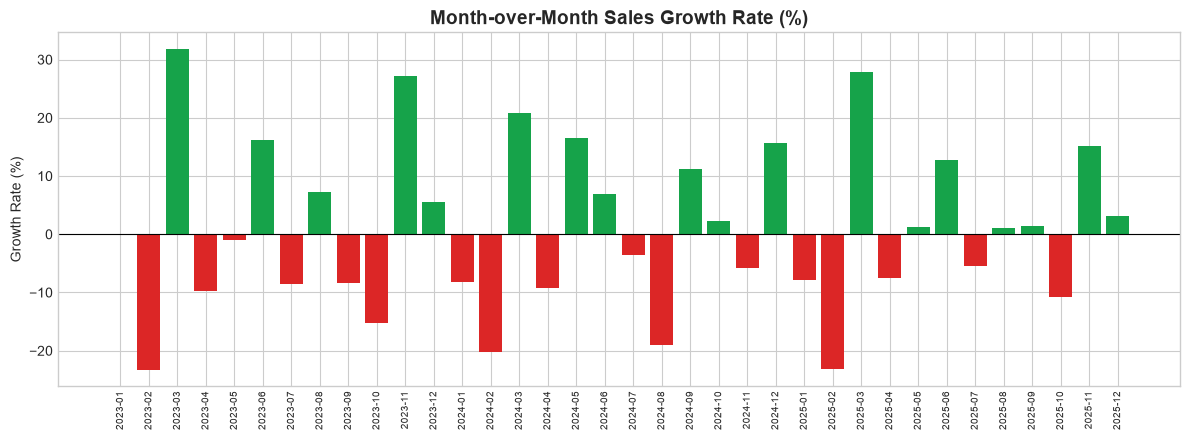

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
colors = ['#16a34a' if v >= 0 else '#dc2626' for v in monthly['Growth_Rate_%'].fillna(0)]
ax.bar(monthly['Year_Month'], monthly['Growth_Rate_%'].fillna(0), color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Month-over-Month Sales Growth Rate (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Growth Rate (%)')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig('outputs/charts/09_monthly_growth_rate.png', dpi=150)
plt.show()

## Step 7 — Category Performance
Which product categories drive the most revenue and profit? This feeds the "Sales by Category" visual on Power BI Page 1, and the Category Profitability visual on Page 2.

In [10]:
category_perf = df.groupby('Category').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique'),
    Quantity=('Quantity', 'sum')
).reset_index()
category_perf['Profit_Margin_%'] = (category_perf['Profit'] / category_perf['Sales'] * 100).round(2)
category_perf = category_perf.sort_values('Sales', ascending=False)
category_perf

,Category,Sales,Profit,Orders,Quantity,Profit_Margin_%
1,Electronics,4400609.13,1392064.02,2415,9582,31.63
2,Furniture,2945305.26,929506.39,2404,9586,31.56
3,Home & Kitchen,1197325.00,375191.43,2461,9812,31.34
0,Clothing,806956.16,255667.00,2389,9780,31.68
4,Office Supplies,429342.75,134907.10,2331,9360,31.42


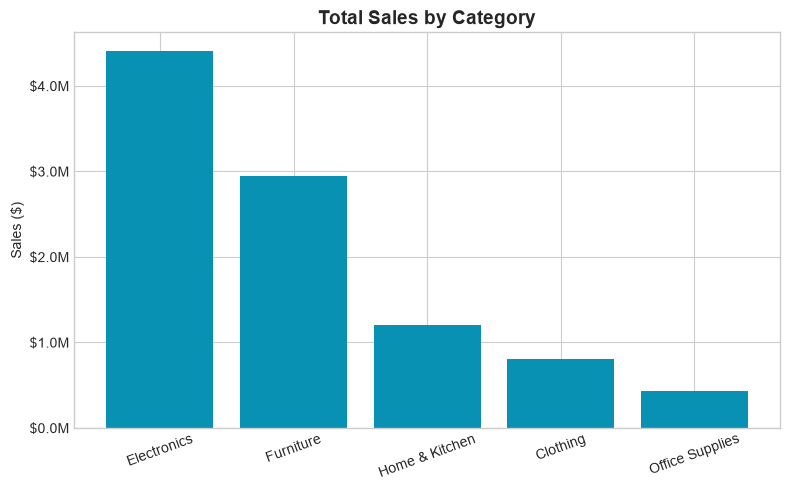

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(category_perf['Category'], category_perf['Sales'], color='#0891b2')
ax.set_title('Total Sales by Category', fontsize=14, fontweight='bold')
ax.set_ylabel('Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('outputs/charts/02_sales_by_category.png', dpi=150)
plt.show()

## Step 8 — Product Ranking (Top 10 / Bottom 10)
Identifies best and worst sellers by revenue — directly informs the Product Analysis page and business recommendations (e.g. discontinue or promote specific SKUs).

In [12]:
product_perf = df.groupby('Product').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Quantity=('Quantity', 'sum')
).reset_index()

top10_products = product_perf.sort_values('Sales', ascending=False).head(10)
bottom10_products = product_perf.sort_values('Sales', ascending=True).head(10)

print("TOP 10 PRODUCTS:")
display(top10_products)
print("\nBOTTOM 10 PRODUCTS:")
display(bottom10_products)

TOP 10 PRODUCTS:


,Product,Sales,Profit,Quantity
19,Smartphone,901449.24,286263.22,1982
6,Headphones,897211.59,290741.62,1991
11,Laptop,891766.87,280207.50,1918
12,Monitor,873928.62,275552.64,1899
9,Keyboard,836252.81,259299.04,1792
5,Desk,646833.15,201180.49,2117
24,Table,613417.96,194671.27,1978
2,Bookshelf,574171.29,181934.08,1877
14,Office Chair,572262.80,179276.82,1859
20,Sofa,538620.06,172443.73,1755



BOTTOM 10 PRODUCTS:


,Product,Sales,Profit,Quantity
15,Paper Pack,79787.35,25184.45,1780
17,Printer,81441.85,25582.26,1771
16,Pen Set,87053.22,27271.83,1870
13,Notebook,87263.09,27270.14,1921
21,Stapler,93797.24,29598.42,2018
0,Backpack,155471.68,49419.82,1889
23,T-Shirt,160125.82,50903.72,1912
7,Jacket,160986.64,50229.21,1970
18,Shoes,162593.87,52293.25,1975
8,Jeans,167778.15,52821.00,2034


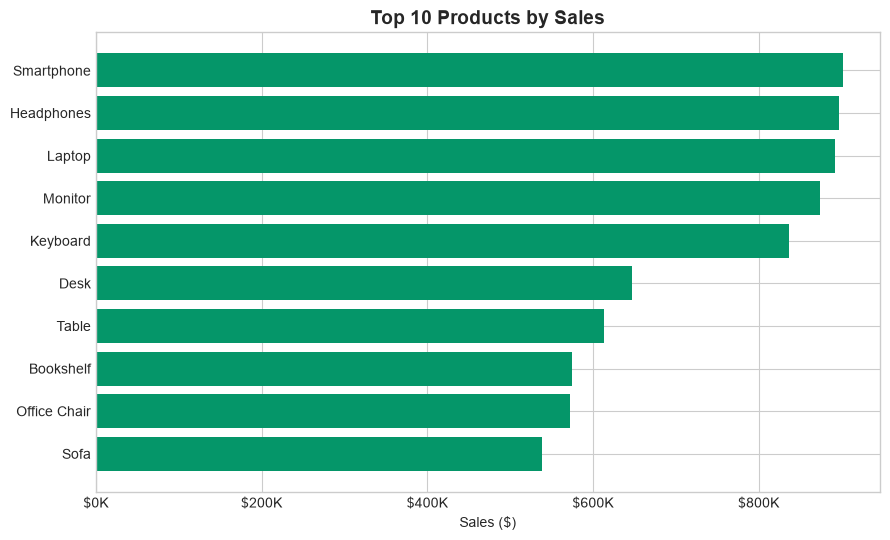

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top10_products['Product'][::-1], top10_products['Sales'][::-1], color='#059669')
ax.set_title('Top 10 Products by Sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Sales ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1000:.0f}K'))
plt.tight_layout()
plt.savefig('outputs/charts/04_top10_products.png', dpi=150)
plt.show()

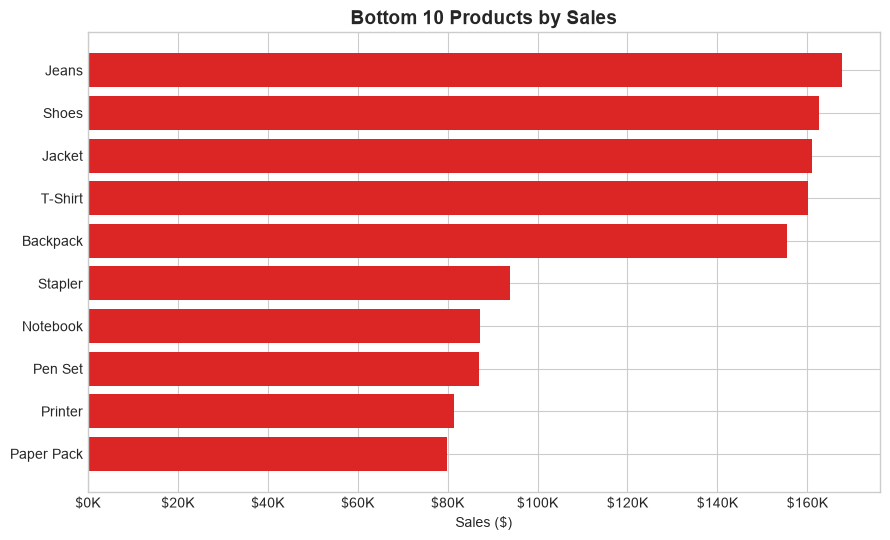

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(bottom10_products['Product'], bottom10_products['Sales'], color='#dc2626')
ax.set_title('Bottom 10 Products by Sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Sales ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1000:.0f}K'))
plt.tight_layout()
plt.savefig('outputs/charts/05_bottom10_products.png', dpi=150)
plt.show()

## Step 9 — Seasonal Trend Analysis
Aggregating by calendar month name (across all 3 years) reveals recurring seasonal patterns — separate from the year-over-year trend in Step 5. This explains *why* certain months dip or spike every year.

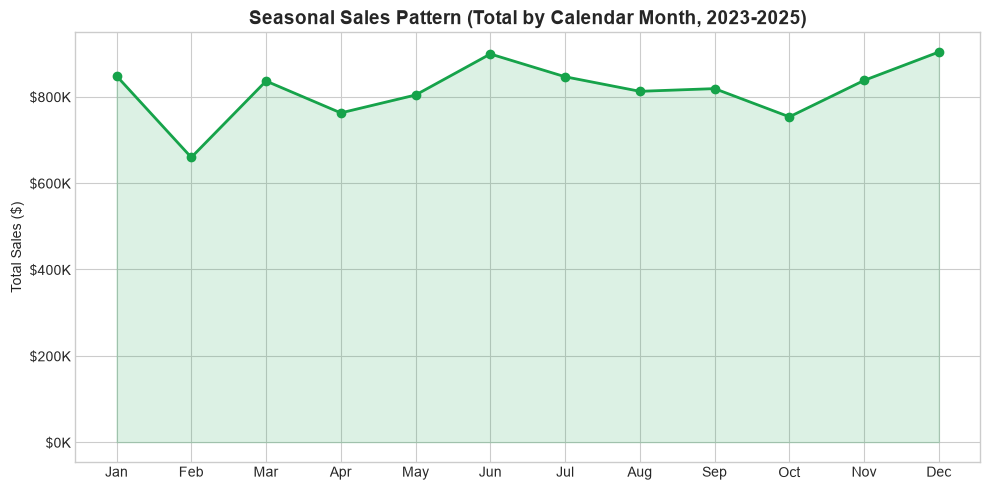

Month_Name
Jan    848024.08
Feb    659365.02
Mar    836114.43
Apr    762348.68
May    803796.87
Jun    898754.45
Jul    846024.75
Aug    812328.02
Sep    818561.32
Oct    753253.14
Nov    837620.81
Dec    903346.73
Name: Sales, dtype: float64

In [15]:
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
seasonal = df.groupby('Month_Name')['Sales'].sum().reindex(month_order)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(seasonal.index, seasonal.values, marker='o', color='#16a34a', linewidth=2)
ax.fill_between(range(len(seasonal)), seasonal.values, alpha=0.15, color='#16a34a')
ax.set_title('Seasonal Sales Pattern (Total by Calendar Month, 2023-2025)', fontsize=14, fontweight='bold')
ax.set_ylabel('Total Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1000:.0f}K'))
plt.tight_layout()
plt.savefig('outputs/charts/08_seasonal_trend.png', dpi=150)
plt.show()

seasonal

## Step 10 — Region Performance
Compares the 5 regions on sales, profit and profit margin — feeds the Regional Analysis page.

In [16]:
region_perf = df.groupby('Region').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index()
region_perf['Profit_Margin_%'] = (region_perf['Profit'] / region_perf['Sales'] * 100).round(2)
region_perf = region_perf.sort_values('Sales', ascending=False)
region_perf

,Region,Sales,Profit,Orders,Profit_Margin_%
2,North,2200082.31,692458.81,2652,31.47
4,West,2130612.16,668163.11,2627,31.36
3,South,1986813.88,628229.02,2409,31.62
0,Central,1731400.20,547370.38,2167,31.61
1,East,1730629.75,551114.62,2145,31.84


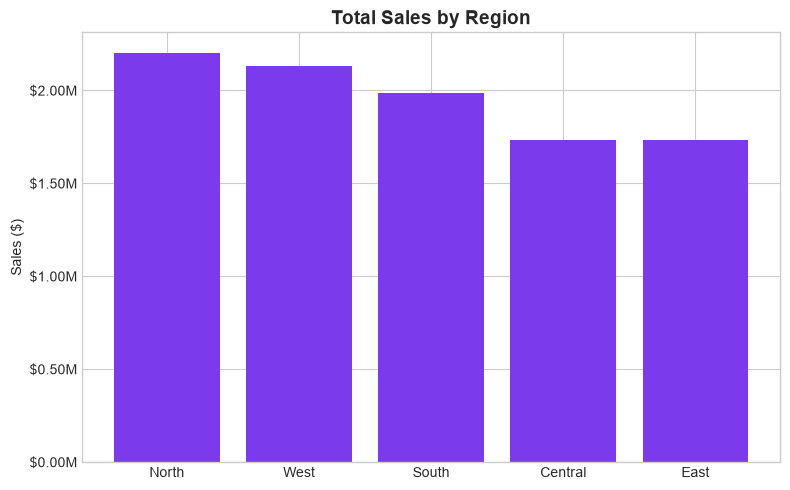

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(region_perf['Region'], region_perf['Sales'], color='#7c3aed')
ax.set_title('Total Sales by Region', fontsize=14, fontweight='bold')
ax.set_ylabel('Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1e6:.2f}M'))
plt.tight_layout()
plt.savefig('outputs/charts/03_sales_by_region.png', dpi=150)
plt.show()

## Step 11 — Customer Segment Performance
Compares Consumer / Corporate / Small Business on sales, profit, and average order value — feeds the Customer Analysis page.

In [18]:
segment_perf = df.groupby('Customer_Segment').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index()
segment_perf['AOV'] = (segment_perf['Sales'] / segment_perf['Orders']).round(2)
segment_perf = segment_perf.sort_values('Sales', ascending=False)
segment_perf

,Customer_Segment,Sales,Profit,Orders,AOV
0,Consumer,4763841.82,1504108.59,6023,790.94
1,Corporate,3025372.67,949249.59,3615,836.89
2,Small Business,1990323.81,633977.76,2362,842.64


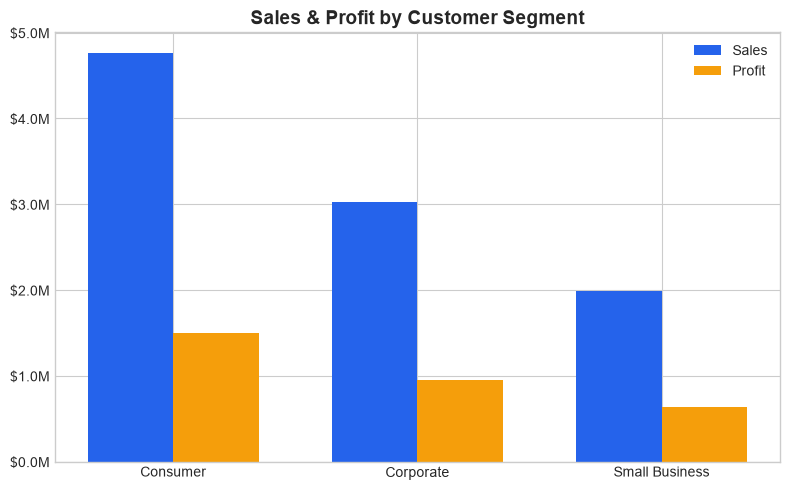

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
x = range(len(segment_perf))
w = 0.35
ax.bar([i - w/2 for i in x], segment_perf['Sales'], width=w, label='Sales', color='#2563eb')
ax.bar([i + w/2 for i in x], segment_perf['Profit'], width=w, label='Profit', color='#f59e0b')
ax.set_xticks(list(x)); ax.set_xticklabels(segment_perf['Customer_Segment'])
ax.set_title('Sales & Profit by Customer Segment', fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))
ax.legend()
plt.tight_layout()
plt.savefig('outputs/charts/06_customer_segment.png', dpi=150)
plt.show()

## Step 12 — Discount vs Profit
Does giving bigger discounts hurt profit margin? We bucket orders into discount bands and compare average profit margin, and also compute the direct correlation.

**Check:** if the correlation is close to 0, discounts in this dataset aren't meaningfully eroding margin — a genuine, evidence-based finding worth including in Phase 6.

In [20]:
df['Discount_Band'] = pd.cut(
    df['Discount'], bins=[-0.01, 0, 0.05, 0.10, 0.15, 1.0],
    labels=['0%', '1-5%', '6-10%', '11-15%', '16%+']
)

discount_analysis = df.groupby('Discount_Band', observed=True).agg(
    Avg_Profit_Margin=('Profit_Margin_%', 'mean'),
    Avg_Sales=('Sales', 'mean'),
    Orders=('Order_ID', 'nunique')
).round(2)

correlation = df['Discount'].corr(df['Profit_Margin_%'])
print(f"Correlation between Discount and Profit Margin %: {correlation:.3f}")
discount_analysis

Correlation between Discount and Profit Margin %: 0.020


,Avg_Profit_Margin,Avg_Sales,Orders
Discount_Band,,,
0%,31.42,882.80,3641
1-5%,31.38,832.78,2988
6-10%,31.37,781.36,2977
11-15%,32.02,740.93,1775
16%+,31.76,703.84,619


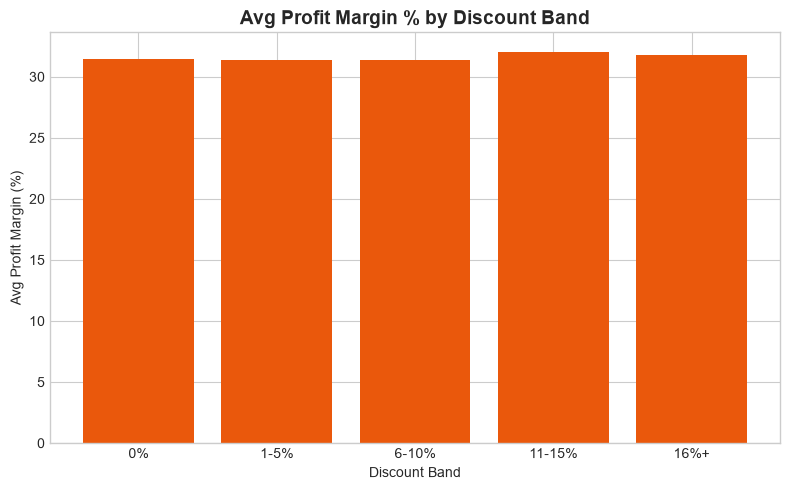

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(discount_analysis.index.astype(str), discount_analysis['Avg_Profit_Margin'], color='#ea580c')
ax.set_title('Avg Profit Margin % by Discount Band', fontsize=14, fontweight='bold')
ax.set_ylabel('Avg Profit Margin (%)'); ax.set_xlabel('Discount Band')
plt.tight_layout()
plt.savefig('outputs/charts/07_discount_vs_profit_margin.png', dpi=150)
plt.show()

## Step 13 — Summary
All KPIs, trend tables, and charts above are saved and ready to feed into:
- **Phase 3:** Excel workbook (`02_sales_analysis.xlsx`)
- **Phase 4:** Power BI dashboard
- **Phase 5:** Tableau dashboard

Charts are saved in `outputs/charts/`. The cleaned dataset is saved as `cleaned_sales.csv` — **use this cleaned file**, not the raw CSV, for Excel/Power BI/Tableau so the derived columns (Year, Month, Profit_Margin_%) are already available.

In [22]:
print("Charts saved in outputs/charts/:")
for f in sorted(os.listdir('outputs/charts')):
    print(" -", f)

Charts saved in outputs/charts/:
 - 01_monthly_sales_trend.png
 - 02_sales_by_category.png
 - 03_sales_by_region.png
 - 04_top10_products.png
 - 05_bottom10_products.png
 - 06_customer_segment.png
 - 07_discount_vs_profit_margin.png
 - 08_seasonal_trend.png
 - 09_monthly_growth_rate.png
